# 02 — Baselines on FD001

In this notebook we:
1. **Reproduce the course notebook approach** (classic ML models, random train/validation split, no RUL cap). This is our **reference**.
2. **Improve it one step at a time**, so we can see the effect of each change:
   - **Step 1:** split train/validation **by engine** instead of by random rows;
   - **Step 2:** also **cap the RUL** at 125 cycles (piecewise-linear target).
3. Evaluate every model on the **official test set** with **RMSE** and the **NASA score** (`src/metrics.py`).
4. Compare all results in one table.

To keep the comparison fair, the **features** (14 sensors from `01_eda`) and the **models with their hyperparameters** are the same in all steps: only the split and the target change.

> **Note:** the course notebook itself is not in this repository. The reference below rebuilds its approach (classic models, random split, no cap) and may differ from it in details such as the exact models or hyperparameters.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

# Project root = parent of the "notebooks" folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.data import FD001_SENSORS, add_train_rul, load_cmapss
from src.metrics import nasa_score, rmse

FIG_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Fixed seed so that splits and models give the same result every run
SEED = 42

## 1. Data

- **Train:** load FD001 and compute the RUL of every row (`last cycle − current cycle`), as in `01_eda`.
- **Features:** the 14 informative sensors selected in `01_eda` (stored in `FD001_SENSORS`).
- **Test:** the C-MAPSS test engines stop *before* failure, and the official RUL file gives the true RUL **at the last recorded cycle only**. So, as is standard for C-MAPSS, we predict **one RUL per test engine, from its last cycle** (100 predictions).

In [2]:
train, test, test_rul = load_cmapss("FD001")
train = add_train_rul(train)

# Last recorded cycle of each test engine -> one row per engine
test_last = test.groupby("unit").tail(1)
# Make sure the engines are in the same order as the true RUL file
test_last = test_last.sort_values("unit")

X_test = test_last[FD001_SENSORS]
y_test = test_rul["true_rul"].values

print("Features:", FD001_SENSORS)
print("Train rows:", len(train), "| Test engines:", len(X_test))

Features: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Train rows: 20631 | Test engines: 100


## 2. Metrics

Both metrics are implemented in `src/metrics.py`:

- **RMSE** (cycles) — average size of the error; early and late errors count the same.
- **NASA score** (PHM08 challenge) — with error `d = predicted − true` for each engine:
  - `d < 0` (early prediction): `exp(−d/13) − 1`
  - `d ≥ 0` (late prediction): `exp(d/10) − 1`

  Summed over the 100 test engines. **Lower is better.** A late prediction is more dangerous (the engine might fail before maintenance), so it is penalised more, and the exponential makes large errors very expensive.

Quick check of the asymmetry: an error of 10 cycles too late costs more than 10 cycles too early.

In [3]:
print("10 cycles early:", round(nasa_score([100], [90]), 3))
print("10 cycles late: ", round(nasa_score([100], [110]), 3))

10 cycles early: 1.158
10 cycles late:  1.718


## 3. Models and evaluation function

Five classic regression models, the same in every step:

| Model | Idea |
|---|---|
| Linear Regression | RUL as a weighted sum of the sensors |
| SVR (Support Vector Regression) | fits a smooth non-linear function (RBF kernel) and ignores errors smaller than a margin; the best model of the course notebook |
| Decision Tree | a sequence of if/else rules on the sensors (depth limited to 10 to reduce overfitting) |
| Random Forest | average of 100 trees, each trained on a random sample of the data |
| XGBoost | trees added one after the other, each one correcting the errors of the previous ones |

**SVR needs scaled inputs.** The RBF kernel measures distances between data points, so a sensor with large values (e.g. sensor_9 ≈ 9000) would dominate one with small values (e.g. sensor_15 ≈ 8.4). We put a `StandardScaler` (mean 0, standard deviation 1 for every sensor) in front of the SVR with `make_pipeline`. The scaler is fitted on the training data only, inside the pipeline, so no information leaks from validation or test. We use `C=10`: on the Step 1 validation set, C = 1, 10 and 100 gave almost the same RMSE.

The function `evaluate_models` trains every model, then computes:
- **validation RMSE** on the validation rows (what we would look at while developing),
- **test RMSE** and **test NASA score** on the 100 official test engines (the real performance).

In [4]:
def make_models():
    """Return a fresh (untrained) copy of each model, with fixed hyperparameters."""
    return {
        "Linear Regression": LinearRegression(),
        # Scale the sensors first, then SVR with an RBF kernel
        "SVR": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=10)),
        "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1),
        "XGBoost": XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=SEED),
    }


def evaluate_models(step_name, X_train, y_train, X_val, y_val):
    """Train every model and return its metrics (one row per model) and its test predictions."""
    rows = []
    test_predictions = {}

    for model_name, model in make_models().items():
        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        test_pred = model.predict(X_test)
        test_predictions[model_name] = test_pred

        rows.append({
            "step": step_name,
            "model": model_name,
            "val_RMSE": rmse(y_val, val_pred),
            "test_RMSE": rmse(y_test, test_pred),
            "test_NASA_score": nasa_score(y_test, test_pred),
        })

    return pd.DataFrame(rows), test_predictions

## 4. Reference: course approach (random split, no cap)

The course notebook splits the training **rows** at random: 80% for training, 20% for validation. The target is the plain RUL, which can be as large as ~360 cycles.

**The problem with a random row split:** consecutive cycles of the same engine are almost identical. With a random split, cycle 50 of engine 1 can be in validation while cycles 49 and 51 are in training. The model has effectively *already seen* that engine, so the validation score **can be too optimistic**: it measures how well we predict engines we trained on, while the test set (and real life) asks how well we predict a **new** engine. This risk grows with models that can recognise an engine from its data, such as the time-window and sequence models we will build later.

In [5]:
X = train[FD001_SENSORS]
y = train["RUL"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED)

results_ref, preds_ref = evaluate_models("0. Reference (random split, no cap)", X_train, y_train, X_val, y_val)
results_ref.round(2)

,step,model,val_RMSE,test_RMSE,test_NASA_score
0,"0. Reference (random split, no cap)",Linear Regression,44.33,32.17,13762.16
1,"0. Reference (random split, no cap)",SVR,41.48,28.03,15338.21
2,"0. Reference (random split, no cap)",Decision Tree,45.97,34.62,2976092.21
3,"0. Reference (random split, no cap)",Random Forest,41.33,33.27,42388.69
4,"0. Reference (random split, no cap)",XGBoost,41.25,33.71,48335.28


## 5. Step 1: split by engine

We now put **whole engines** either in training or in validation (80 / 20 engines), using `GroupShuffleSplit` with the engine id as the group. No engine appears in both sets, so the validation set now looks like the test set: engines the model has never seen.

We only change the split; the target is still the uncapped RUL.

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(splitter.split(train, groups=train["unit"]))

train_part = train.iloc[train_idx]
val_part = train.iloc[val_idx]

# Check: no engine is in both sets
common_engines = set(train_part["unit"]) & set(val_part["unit"])
print("Train engines:", train_part["unit"].nunique(), "| Validation engines:", val_part["unit"].nunique())
print("Engines in both sets:", len(common_engines))

Train engines: 80 | Validation engines: 20
Engines in both sets: 0


In [7]:
results_step1, preds_step1 = evaluate_models(
    "1. Engine split, no cap",
    train_part[FD001_SENSORS], train_part["RUL"],
    val_part[FD001_SENSORS], val_part["RUL"],
)
results_step1.round(2)

,step,model,val_RMSE,test_RMSE,test_NASA_score
0,"1. Engine split, no cap",Linear Regression,38.14,32.12,13563.08
1,"1. Engine split, no cap",SVR,34.94,28.23,13985.34
2,"1. Engine split, no cap",Decision Tree,40.79,39.42,906984.54
3,"1. Engine split, no cap",Random Forest,35.41,34.38,69204.44
4,"1. Engine split, no cap",XGBoost,35.25,33.30,42348.71


## 6. Step 2: engine split + RUL capped at 125

In `01_eda` we saw that the sensors stay flat while the engine is healthy and only start to change in the last ~100–150 cycles. So the sensors **cannot** tell RUL = 300 from RUL = 200, and asking the model to do so only adds noise.

**RUL capping (piecewise-linear target):** we replace the target with `min(RUL, 125)`.
- Early in life the target is a constant 125 ("healthy").
- In the last 125 cycles it decreases linearly to 0.

We use the **same engine split** as in Step 1. The cap is applied only to the **training and validation targets**. On the test set we still compare to the **true** RUL from the RUL file, so test results stay comparable across all steps.

*Note:* the validation RMSE of this step is measured against the capped target, so it is not directly comparable to the validation RMSE of the earlier steps. The **test** columns are comparable.

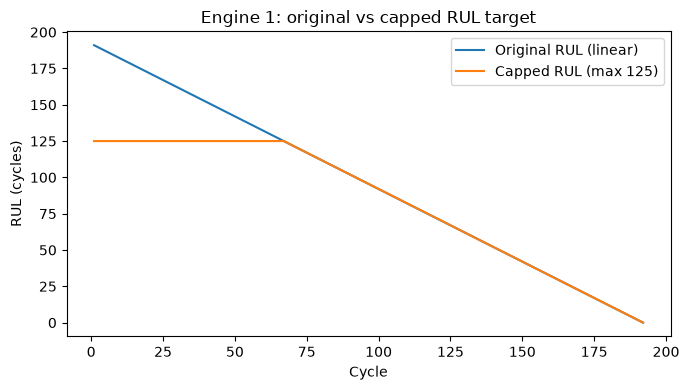

In [8]:
RUL_CAP = 125

# np.minimum keeps the smaller of the two values, row by row
y_train_capped = np.minimum(train_part["RUL"], RUL_CAP)
y_val_capped = np.minimum(val_part["RUL"], RUL_CAP)

# Plot for one engine: original vs capped target
engine_1 = train[train["unit"] == 1]
plt.figure(figsize=(7, 4))
plt.plot(engine_1["cycle"], engine_1["RUL"], label="Original RUL (linear)")
plt.plot(engine_1["cycle"], np.minimum(engine_1["RUL"], RUL_CAP), label=f"Capped RUL (max {RUL_CAP})")
plt.xlabel("Cycle")
plt.ylabel("RUL (cycles)")
plt.title("Engine 1: original vs capped RUL target")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_rul_cap.png", dpi=150)
plt.show()

In [9]:
results_step2, preds_step2 = evaluate_models(
    "2. Engine split + cap 125",
    train_part[FD001_SENSORS], y_train_capped,
    val_part[FD001_SENSORS], y_val_capped,
)
results_step2.round(2)

,step,model,val_RMSE,test_RMSE,test_NASA_score
0,2. Engine split + cap 125,Linear Regression,20.43,21.86,1299.10
1,2. Engine split + cap 125,SVR,17.46,19.59,1483.71
2,2. Engine split + cap 125,Decision Tree,19.65,20.95,11274.44
3,2. Engine split + cap 125,Random Forest,17.17,17.58,843.23
4,2. Engine split + cap 125,XGBoost,16.91,18.11,998.61


## 7. Comparison of all results

In [10]:
all_results = pd.concat([results_ref, results_step1, results_step2], ignore_index=True)
all_results.to_csv(METRICS_DIR / "02_baselines_fd001.csv", index=False)

all_results.round(2)

,step,model,val_RMSE,test_RMSE,test_NASA_score
0,"0. Reference (random split, no cap)",Linear Regression,44.33,32.17,13762.16
1,"0. Reference (random split, no cap)",SVR,41.48,28.03,15338.21
2,"0. Reference (random split, no cap)",Decision Tree,45.97,34.62,2976092.21
3,"0. Reference (random split, no cap)",Random Forest,41.33,33.27,42388.69
4,"0. Reference (random split, no cap)",XGBoost,41.25,33.71,48335.28
5,"1. Engine split, no cap",Linear Regression,38.14,32.12,13563.08
6,"1. Engine split, no cap",SVR,34.94,28.23,13985.34
7,"1. Engine split, no cap",Decision Tree,40.79,39.42,906984.54
8,"1. Engine split, no cap",Random Forest,35.41,34.38,69204.44
9,"1. Engine split, no cap",XGBoost,35.25,33.30,42348.71


The same test results arranged as tables (rows = models, columns = steps), which makes each change easier to see:

In [11]:
print("Test RMSE (cycles):")
display(all_results.pivot(index="model", columns="step", values="test_RMSE").round(2))

print("Test NASA score:")
display(all_results.pivot(index="model", columns="step", values="test_NASA_score").round(0))

Test RMSE (cycles):


step,"0. Reference (random split, no cap)","1. Engine split, no cap",2. Engine split + cap 125
model,,,
Decision Tree,34.62,39.42,20.95
Linear Regression,32.17,32.12,21.86
Random Forest,33.27,34.38,17.58
SVR,28.03,28.23,19.59
XGBoost,33.71,33.30,18.11


Test NASA score:


step,"0. Reference (random split, no cap)","1. Engine split, no cap",2. Engine split + cap 125
model,,,
Decision Tree,2976092.0,906985.0,11274.0
Linear Regression,13762.0,13563.0,1299.0
Random Forest,42389.0,69204.0,843.0
SVR,15338.0,13985.0,1484.0
XGBoost,48335.0,42349.0,999.0


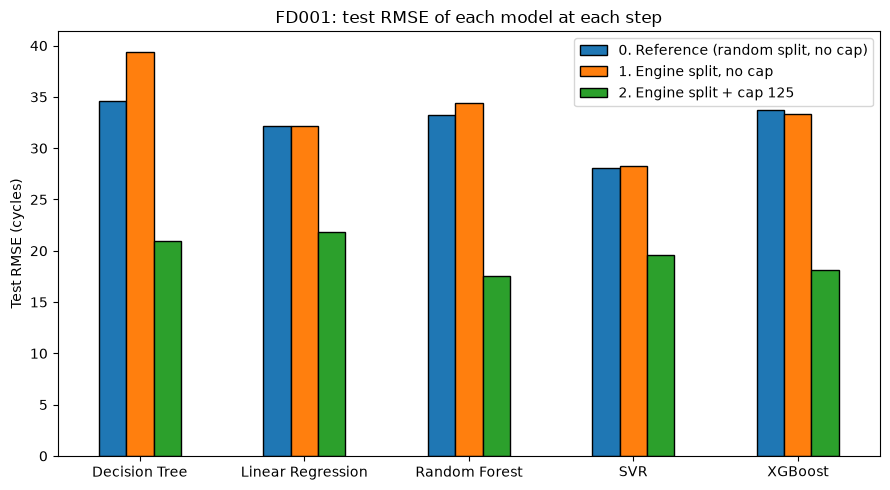

In [12]:
# Bar chart of test RMSE: one group per model, one bar per step
rmse_table = all_results.pivot(index="model", columns="step", values="test_RMSE")
rmse_table.plot(kind="bar", figsize=(9, 5), edgecolor="black")
plt.ylabel("Test RMSE (cycles)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.title("FD001: test RMSE of each model at each step")
plt.legend(title="")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_baselines_test_rmse.png", dpi=150)
plt.show()

### Predicted vs true RUL on the test set

We compare the Random Forest of the reference with the Random Forest of Step 2. Points on the dashed diagonal are perfect predictions; points **above** it are **late** predictions (the dangerous ones), points below are early.

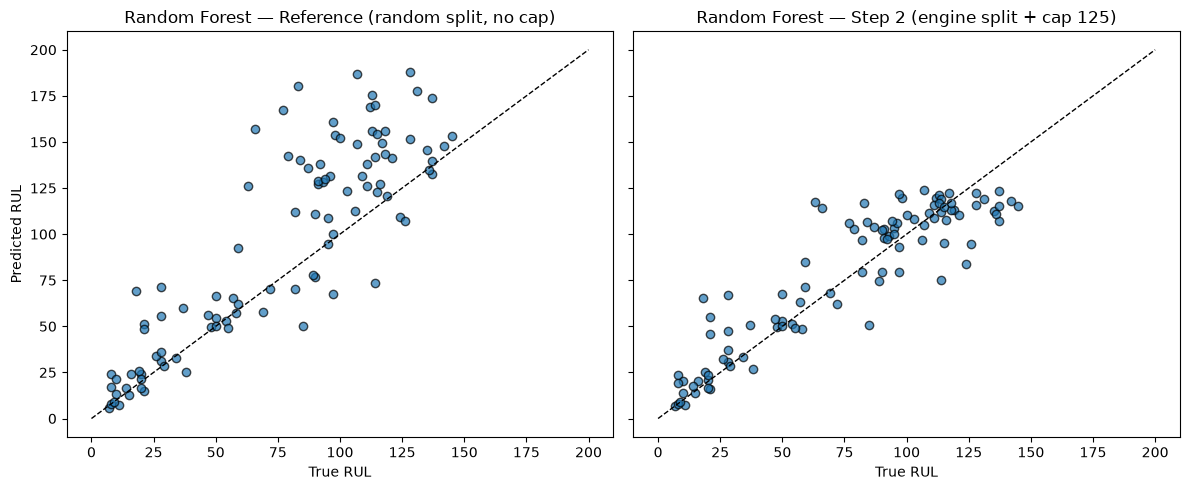

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, preds, title in [
    (axes[0], preds_ref["Random Forest"], "Reference (random split, no cap)"),
    (axes[1], preds_step2["Random Forest"], "Step 2 (engine split + cap 125)"),
]:
    ax.scatter(y_test, preds, alpha=0.7, edgecolor="black")
    ax.plot([0, 200], [0, 200], "k--", linewidth=1)  # perfect prediction line
    ax.set_xlabel("True RUL")
    ax.set_title(f"Random Forest — {title}")

axes[0].set_ylabel("Predicted RUL")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_pred_vs_true_rf.png", dpi=150)
plt.show()

## 8. Discussion

**Reference (course approach).** **SVR** is the best model with a test RMSE of **28.0** cycles; the other models are at 32–35. The NASA scores are very large for every model (from ~14,000 up to millions). The scatter plot shows why: for engines with a high true RUL, the model often predicts far too much (late predictions above the diagonal), and the NASA score punishes late errors exponentially. The Decision Tree has the worst score because a few very late predictions dominate the sum.

Our best reference RMSE (SVR, 28.0) is close to the ≈ 26 of the course notebook, so this reconstruction is a reasonable reference. The remaining gap probably comes from small differences in hyperparameters, features or how the test set is evaluated (we use one prediction per engine at its last cycle, the standard C-MAPSS protocol).

**Step 1: engine split.** Test results barely change for Linear Regression, SVR, Random Forest and XGBoost, as expected: the models still train on ~80% of the data with the same target. The single Decision Tree gets worse (34.6 → 39.4): one tree is unstable and changes a lot when the training rows change, which is why averaging many trees (Random Forest) helps. In this experiment the random split did **not** give an optimistic validation RMSE (validation RMSE was actually *higher* than with the engine split, because a different set of rows ends up in validation). With single-cycle features the noise is too strong for the models to "recognise" an engine, so leakage has little effect here. We still keep the engine split: it is the correct protocol, and it will matter for the windowed and sequence models. Note also that the validation RMSE is computed on all cycles (RUL up to ~360), while the test only contains RUL ≤ 145, so the two numbers are not directly comparable.

**Step 2: RUL capped at 125.** This is the big improvement: the best test RMSE drops from 28.0 (SVR, reference) to **17.6** (Random Forest; XGBoost 18.1, SVR 19.6), and the best NASA score drops from ~14,000 to **843**. Every model improves, and SVR is no longer the best one: with the capped target the tree ensembles do better. The model no longer tries to guess large RUL values that the sensors cannot explain; it predicts "healthy, ~125" early in life and focuses on the degradation phase. The price is visible on the right of the scatter plot: engines with a true RUL above 125 are always under-predicted (early predictions), but early errors are the safe side for maintenance.

**Next steps:** time windows over the sensor sequences (to reduce noise and use the trend, not one cycle), then LSTM / TransLSTM models.